<a href="https://colab.research.google.com/github/nagayada/Nag_New_Repo/blob/main/RR_Car_Price_Prediction_Nagaraju_yada.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Vehicle Prices Using Regression Models

## **Objectives**  
The primary goal of this project is to develop a robust regression model to predict used car prices for a reseller based on various listed features and specifications. In addition to predicting prices, the project focuses on identifying feature importance and mitigating overfitting through the application of regularisation techniques.

There can be several business objectives for this, such as:

* **Price Prediction**: Model car prices based on features like mileage, fuel type, and performance.
* **Market Analysis**: Explore trends and preferences in the used car market, by type, region, or other metrics.
* **Feature Importance**: Identify the most important factors influencing car prices (e.g., fuel type, mileage, age).

### **Tasks Overview**
The data pipeline for this task involves the following steps:  
1. **Dataset Overview**   
2. **Data Preprocessing**
3. **Data Visualisation & Exploration**
4. **Model Building**
3. **Regularisation**

## **1 Data Understanding**

| **Variable** | **Description** |
--------|--------------|
| `make_model` | The brand and model of the vehicle (e.g., 'Audi A1'). |
| `body_type` | The body style of the vehicle, such as Sedan, Compact, or Station Wagon. |
| `price`  | The listed price of the car in currency. |
| `vat`  | Indicates the VAT status for the vehicle's price (e.g., VAT deductible, Price negotiable). |
| `km` | The total mileage (in kilometers) of the vehicle, indicating its usage. |
| `Type` | Condition of the vehicle, whether it's 'Used' or 'New'.|
| `Fuel` | Type of fuel the vehicle uses, such as 'Diesel', 'Benzine', etc. |
| `Gears` | The number of gears in the vehicle's transmission. |
| `Comfort_Convenience` | Comfort and convenience features, such as 'Air conditioning', 'Leather steering wheel', 'Cruise control', and more. |
| `Entertainment_Media` | Media features available in the vehicle, including 'Bluetooth', 'MP3', 'Radio', etc. |
| `Extras` | Additional features like 'Alloy wheels', 'Sport suspension', etc.|
| `Safety_Security` | Safety features like 'ABS', 'Airbags', 'Electronic stability control', 'Isofix', etc.  |
| `age` | Age of the car (calculated based on the model year). |
| `Previous_Owners`| The number of previous owners the car has had. |
| `hp_kW` | Engine power in kilowatts (kW), indicating the performance capacity of the engine.|
| `Inspection_new` | Indicates whether the car has recently undergone an inspection (1 for yes, 0 for no). |
| `Paint_Type`| The type of paint on the car, such as 'Metallic', 'Matte', etc. |
| `Upholstery_type` | The material used for the interior upholstery, such as 'Cloth', 'Leather', etc.|
| `Gearing_Type` | The type of transmission the car uses, either 'Automatic' or 'Manual'. |
| `Displacement_cc` | The engine displacement in cubic centimeters (cc), indicating the size of the engine.|
| `Weight_kg` | The total weight of the vehicle in kilograms.|
| `Drive_chain` | The type of drivetrain, indicating whether it's 'Front' or 'Rear' wheel drive. |
| `cons_comb`  | The combined fuel consumption in liters per 100 kilometers.|

### **1.1 Data Loading**

**Importing Necessary Libraries**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

#### **1.1.1**
Load the dataset

In [3]:
df = pd.read_csv('/content/Car_Price_data.csv')
display(df.head())
print(df.info())

,make_model,body_type,price,vat,km,Type,Fuel,Gears,Comfort_Convenience,Entertainment_Media,...,Previous_Owners,hp_kW,Inspection_new,Paint_Type,Upholstery_type,Gearing_Type,Displacement_cc,Weight_kg,Drive_chain,cons_comb
0,Audi A1,Sedans,15770,VAT deductible,56013.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,Hands-free equipment,On-board comput...",...,2.0,66.0,1,Metallic,Cloth,Automatic,1422.0,1220.0,front,3.8
1,Audi A1,Sedans,14500,Price negotiable,80000.0,Used,Benzine,7.0,"Air conditioning,Automatic climate control,Hil...","Bluetooth,Hands-free equipment,On-board comput...",...,1.0,141.0,0,Metallic,Cloth,Automatic,1798.0,1255.0,front,5.6
2,Audi A1,Sedans,14640,VAT deductible,83450.0,Used,Diesel,7.0,"Air conditioning,Cruise control,Electrical sid...","MP3,On-board computer",...,1.0,85.0,0,Metallic,Cloth,Automatic,1598.0,1135.0,front,3.8
3,Audi A1,Sedans,14500,VAT deductible,73000.0,Used,Diesel,6.0,"Air suspension,Armrest,Auxiliary heating,Elect...","Bluetooth,CD player,Hands-free equipment,MP3,O...",...,1.0,66.0,0,Metallic,Cloth,Automatic,1422.0,1195.0,front,3.8
4,Audi A1,Sedans,16790,VAT deductible,16200.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,CD player,Hands-free equipment,MP3,O...",...,1.0,66.0,1,Metallic,Cloth,Automatic,1422.0,1135.0,front,4.1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15915 entries, 0 to 15914
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make_model           15915 non-null  object 
 1   body_type            15915 non-null  object 
 2   price                15915 non-null  int64  
 3   vat                  15915 non-null  object 
 4   km                   15915 non-null  float64
 5   Type                 15915 non-null  object 
 6   Fuel                 15915 non-null  object 
 7   Gears                15915 non-null  float64
 8   Comfort_Convenience  15915 non-null  object 
 9   Entertainment_Media  15915 non-null  object 
 10  Extras               15915 non-null  object 
 11  Safety_Security      15915 non-null  object 
 12  age                  15915 non-null  float64
 13  Previous_Owners      15915 non-null  float64
 14  hp_kW                15915 non-null  float64
 15  Inspection_new       15915 non-null 

## **2 Analysis and Feature Engineering** <font color =red> [35 marks] </font>



### **2.1 Preliminary Analysis and Frequency Distributions** <font color = red> [13 marks] </font>

#### **2.1.1** <font color =red> [1 marks] </font>
Check and fix missing values.

In [4]:
# Find the proportion of missing values in each column
missing_proportions = df.isnull().mean()
display(missing_proportions[missing_proportions > 0])

# Inform if there are no missing values
if (missing_proportions == 0).all():
    print("No missing values found in the dataset.")

,0


No missing values found in the dataset.


**From the features, identify the target feature and numerical and categorical predictors. Select the numerical and categorical features carefully as they will be used in analysis.**

#### **2.1.2** <font color =red> [3 marks] </font>
Identify numerical predictors and plot their frequency distributions.

Numerical Columns Identified: ['price', 'km', 'Gears', 'age', 'Previous_Owners', 'hp_kW', 'Inspection_new', 'Displacement_cc', 'Weight_kg', 'cons_comb']


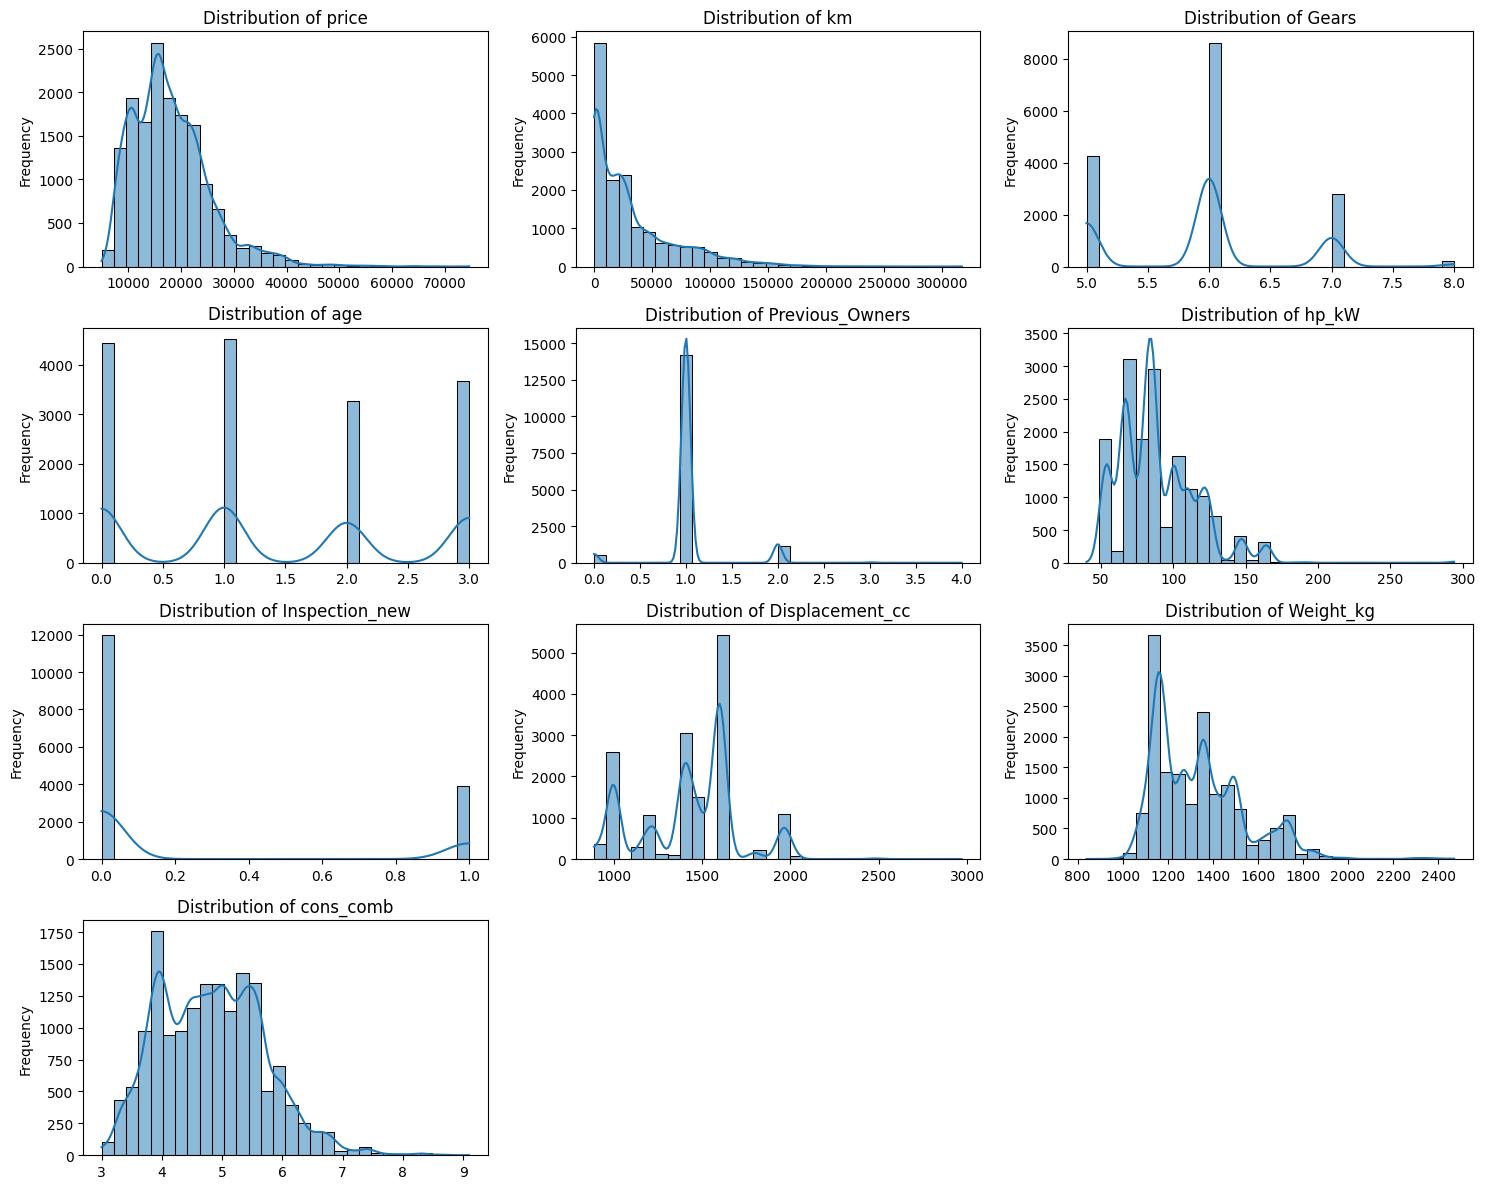

In [5]:
# Identify numerical features and plot histograms


numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("Numerical Columns Identified:", numerical_cols)

# Plot frequency distributions (histograms) for numerical columns
plt.figure(figsize=(15, 12))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(4, 3, i)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
    plt.xlabel('')
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

#### **2.1.3** <font color =red> [3 marks] </font>
Identify categorical predictors and plot their frequency distributions.

Categorical Predictors Identified: ['make_model', 'body_type', 'vat', 'Type', 'Fuel', 'Paint_Type', 'Upholstery_type', 'Gearing_Type', 'Drive_chain']


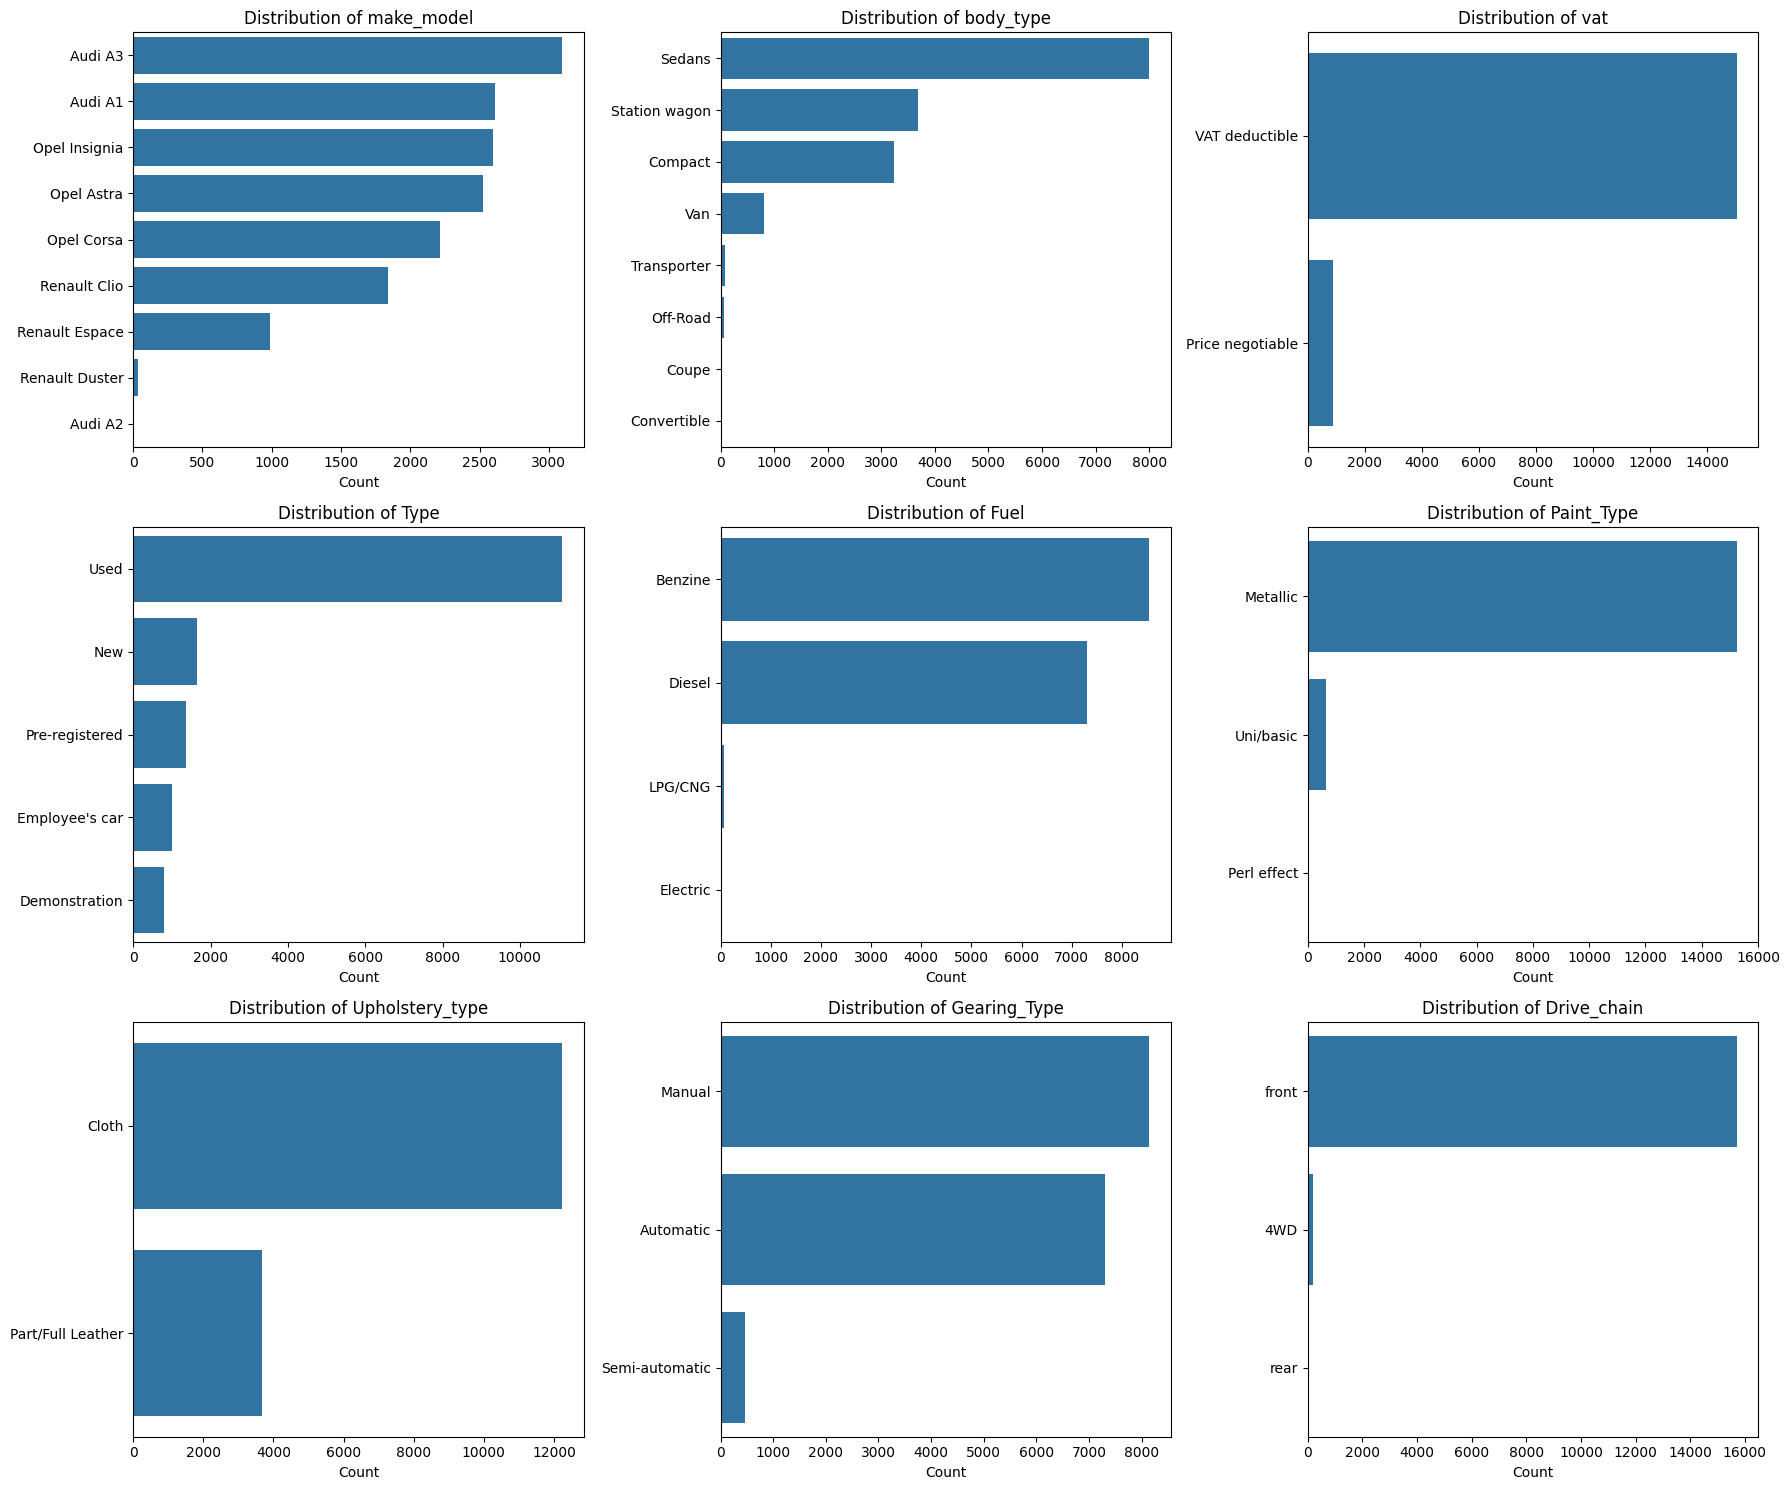

In [6]:
# Identify categorical columns and check their frequency distributions

#Identify categorical columns (excluding columns containing lists)
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

# We will exclude the nested list columns for now since they need specialized engineering
spec_cols = ['Comfort_Convenience', 'Entertainment_Media', 'Extras', 'Safety_Security']
categorical_predictors = [col for col in categorical_cols if col not in spec_cols]

print("Categorical Predictors Identified:", categorical_predictors)

# Plot the distribution counts for major categorical columns
plt.figure(figsize=(18, 15))
for i, col in enumerate(categorical_predictors[:9], 1): # Visualizing the top 9 categorical predictors
    plt.subplot(3, 3, i)
    sns.countplot(data=df, y=col, order=df[col].value_counts().index[:10])
    plt.title(f'Distribution of {col}')
    plt.xlabel('Count')
    plt.ylabel('')

plt.tight_layout()
plt.show()

**Note**: Look carefully at the values stored in columns `["Comfort_Convenience", "Entertainment_Media", "Extras", "Safety_Security"]`.

Should they be considered categorical? Should they be dropped or handled any other way?

#### **2.1.4** <font color =red> [3 marks] </font>
Fix columns with low frequency values and class imbalances.

Some information regarding values in the `Type` column that may help:
- *'Pre-registered'* cars are ones which have already been registered previously by the seller.
- *'New'* cars are not necessarily new cars, but new-like cars. These might also have multiple owners due to multiple pre-registrations as well.
- *'Employee's car'* are cars used by employees over a short period of time and small distance.
- *'Demonstration'* cars are used for trial purposes and also driven for a short time and distance.

Based on these, you can handle this particular column. For other columns, decide a strategy on your own.

In [7]:
# We can consolidate the low frequency/related types in the 'Type' column
# Pre-registered, Employee's car, and Demonstration can be grouped or simplified if needed.
print("Before mapping - Type distribution:")
print(df['Type'].value_counts())

# Let's clean rare values in 'Fuel' and 'Type'
df['Fuel'] = df['Fuel'].replace({
    'LPG/CNG': 'Alternative_Fuel',
    'Electric': 'Alternative_Fuel'
})

# For Type, let's keep 'Used' and 'New', and consolidate others into 'Used' or another category if desired.
# Here we map 'Pre-registered', 'Employee\'s car', and 'Demonstration' to 'Used'
df['Type'] = df['Type'].replace({
    'Pre-registered': 'Used',
    'Employee\'s car': 'Used',
    'Demonstration': 'Used'
})

print("\nAfter mapping - Type distribution:")
print(df['Type'].value_counts())
print("\nAfter mapping - Fuel distribution:")
print(df['Fuel'].value_counts())

Before mapping - Type distribution:
Type
Used              11095
New                1649
Pre-registered     1364
Employee's car     1011
Demonstration       796
Name: count, dtype: int64

After mapping - Type distribution:
Type
Used    14266
New      1649
Name: count, dtype: int64

After mapping - Fuel distribution:
Fuel
Benzine             8548
Diesel              7298
Alternative_Fuel      69
Name: count, dtype: int64


#### **2.1.5** <font color =red> [3 marks] </font>
Identify target variable and plot the frequency distributions. Apply necessary transformations.

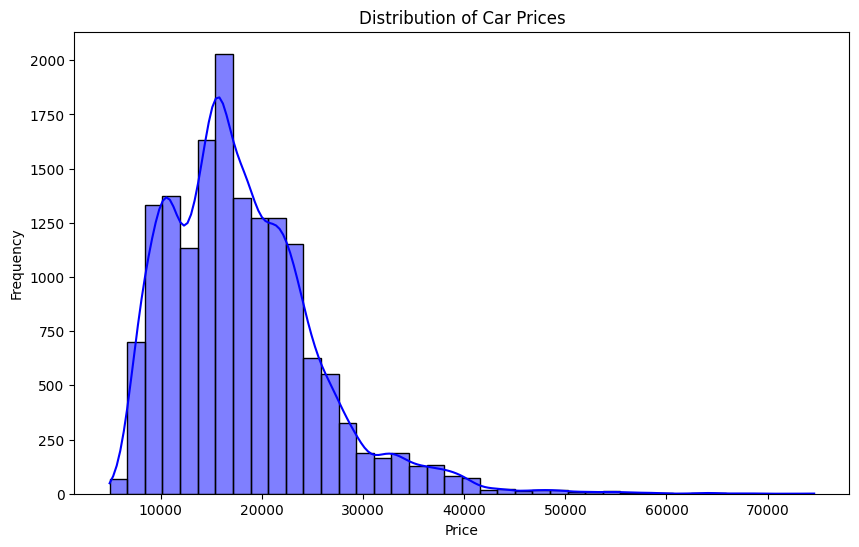

In [8]:
plt.figure(figsize=(10, 6))
sns.histplot(df['price'], kde=True, bins=40, color='blue')
plt.title('Distribution of Car Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

**The target variable seems to be skewed. Perform suitable transformation on the target.**

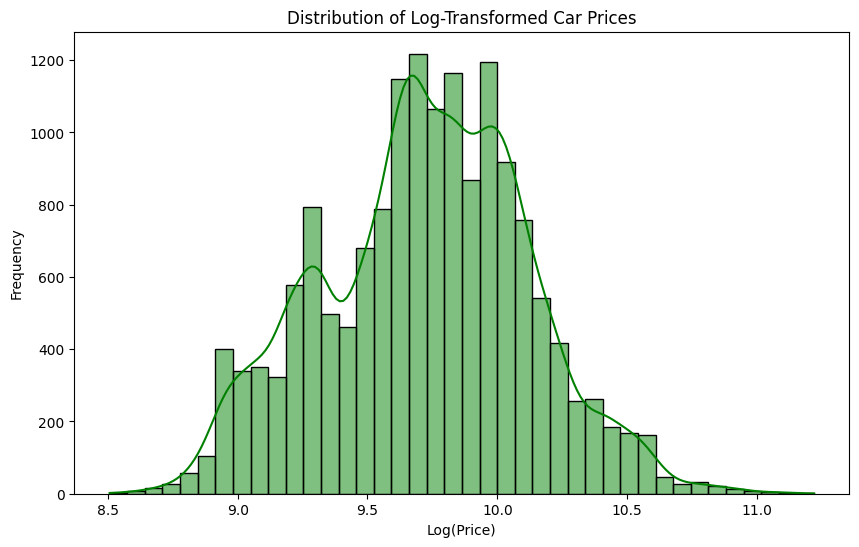

In [9]:
# Transform the target feature
df['log_price'] = np.log(df['price'])

# Plotting the newly transformed target feature to verify normality
plt.figure(figsize=(10, 6))
sns.histplot(df['log_price'], kde=True, bins=40, color='green')
plt.title('Distribution of Log-Transformed Car Prices')
plt.xlabel('Log(Price)')
plt.ylabel('Frequency')
plt.show()

### **2.2 Correlation analysis** <font color = red> [6 marks] </font>

#### **2.2.1** <font color =red> [3 marks] </font>
Plot the correlation map between features and target variable.

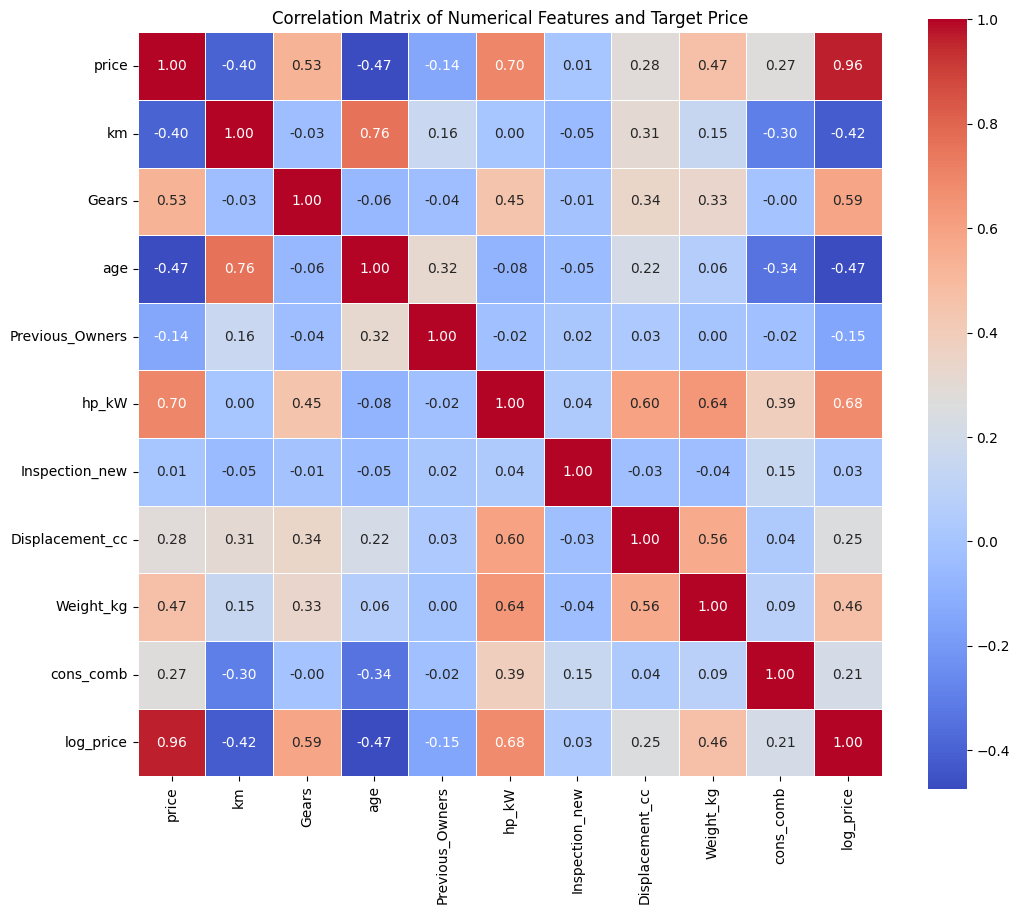

In [11]:
#visualization correlation

# Calculate the correlation matrix of numerical features
numerical_df = df[numerical_cols + ['log_price']]
corr_matrix = numerical_df.corr()

# Plot the correlation heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True, linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features and Target Price')
plt.show()

#### **2.2.2** <font color =red> [3 marks] </font>
Analyse correlation between categorical features and target variable.

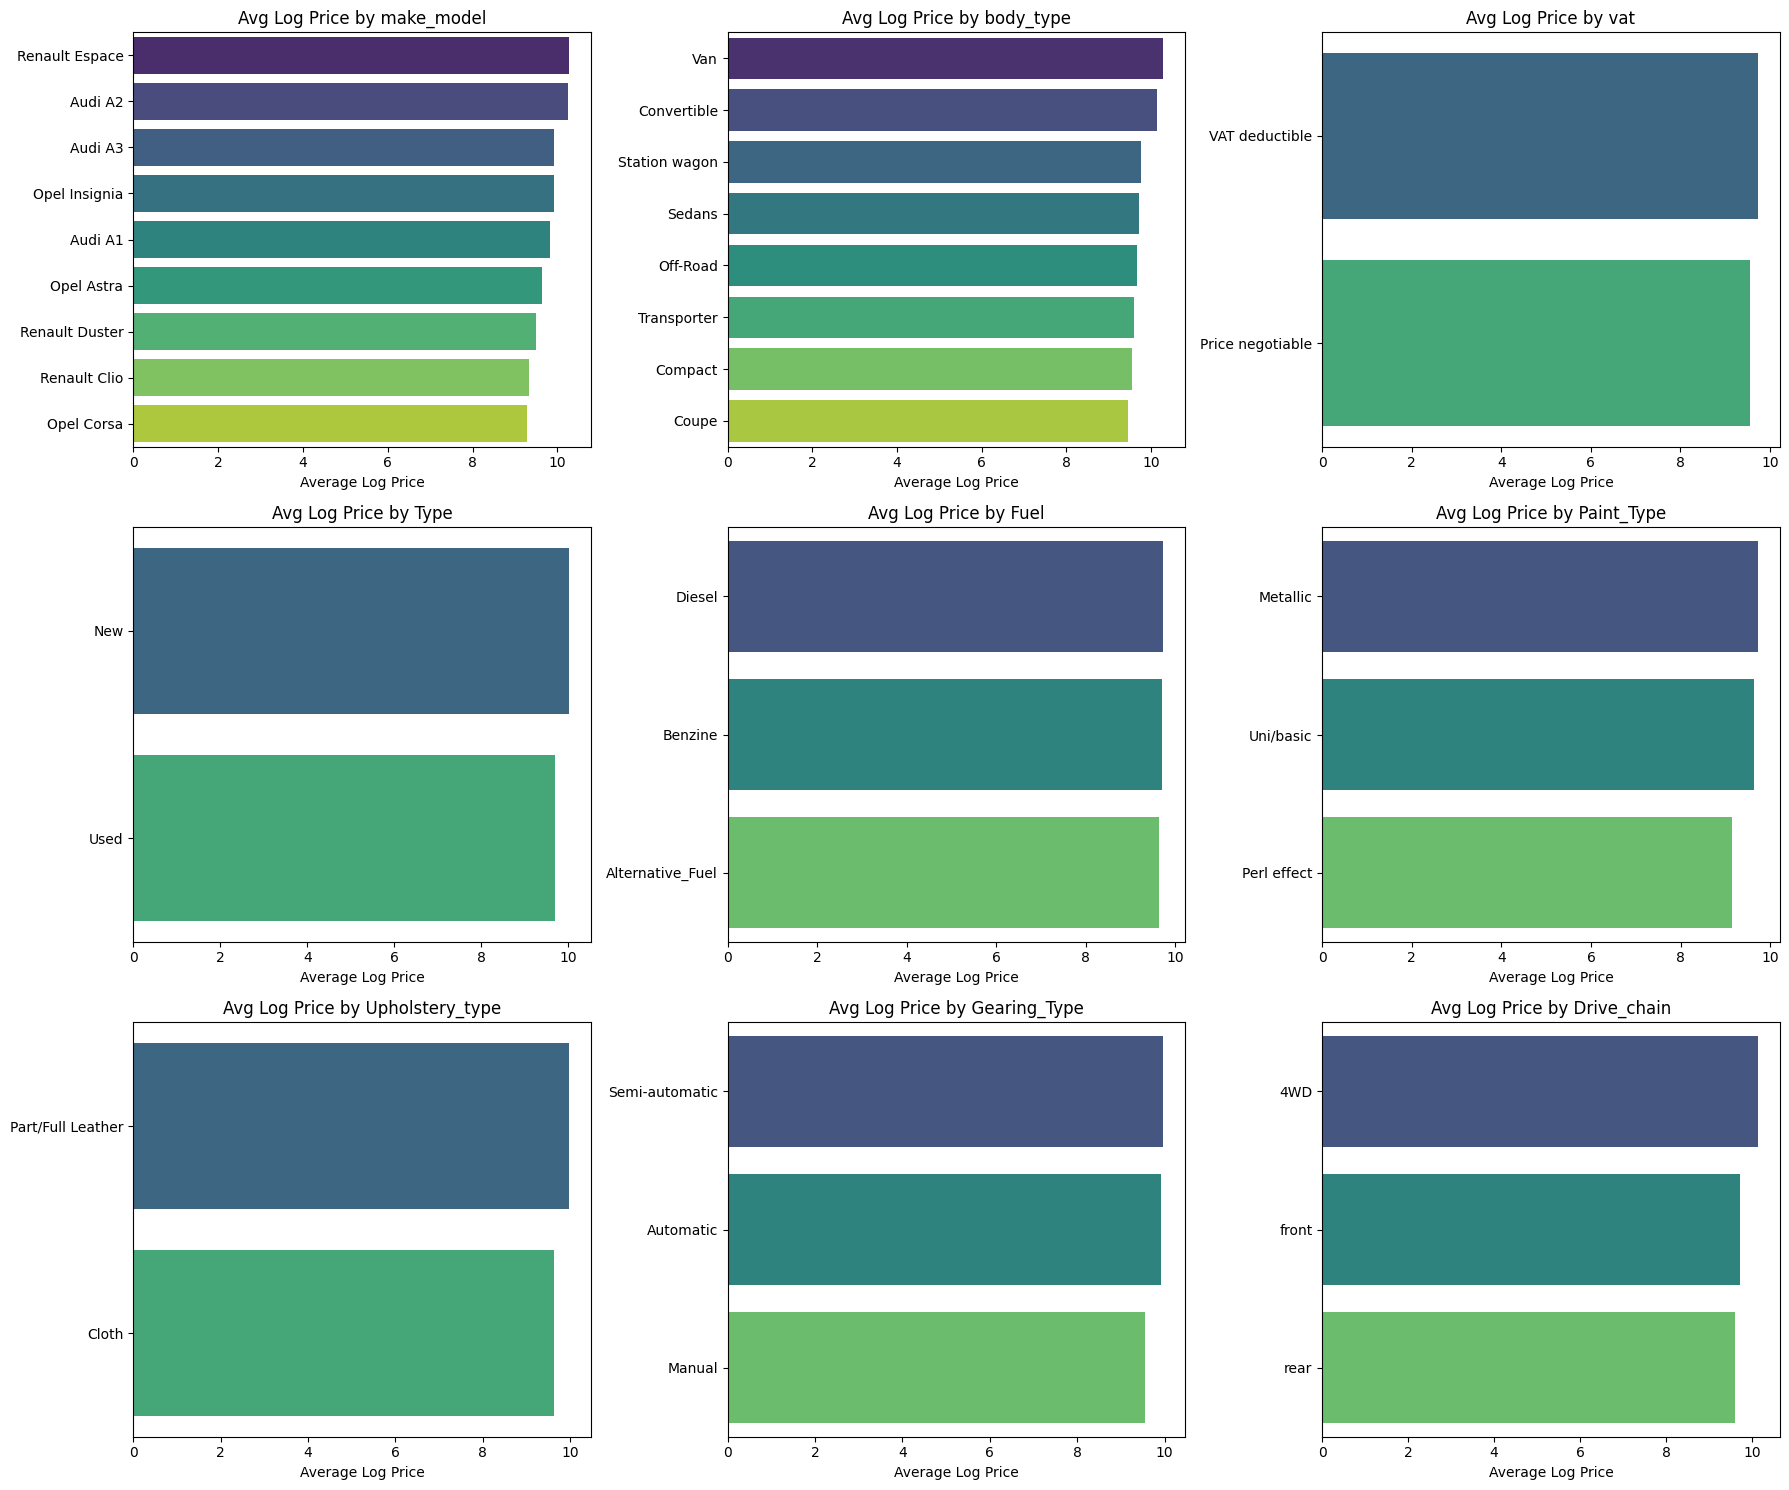

In [12]:
## Comparing average values of target for different categories

plt.figure(figsize=(18, 15))
for i, col in enumerate(categorical_predictors[:9], 1):
    plt.subplot(3, 3, i)
    # Group by category and calculate mean log_price
    group_data = df.groupby(col)['log_price'].mean().sort_values(ascending=False).head(10)
    sns.barplot(x=group_data.values, y=group_data.index, palette='viridis')
    plt.title(f'Avg Log Price by {col}')
    plt.xlabel('Average Log Price')
    plt.ylabel('')

plt.tight_layout()
plt.show()

### **2.3 Outlier analysis** <font color = red> [5 marks] </font>

#### **2.3.1** <font color =red> [2 marks] </font>
Identify potential outliers in the data.

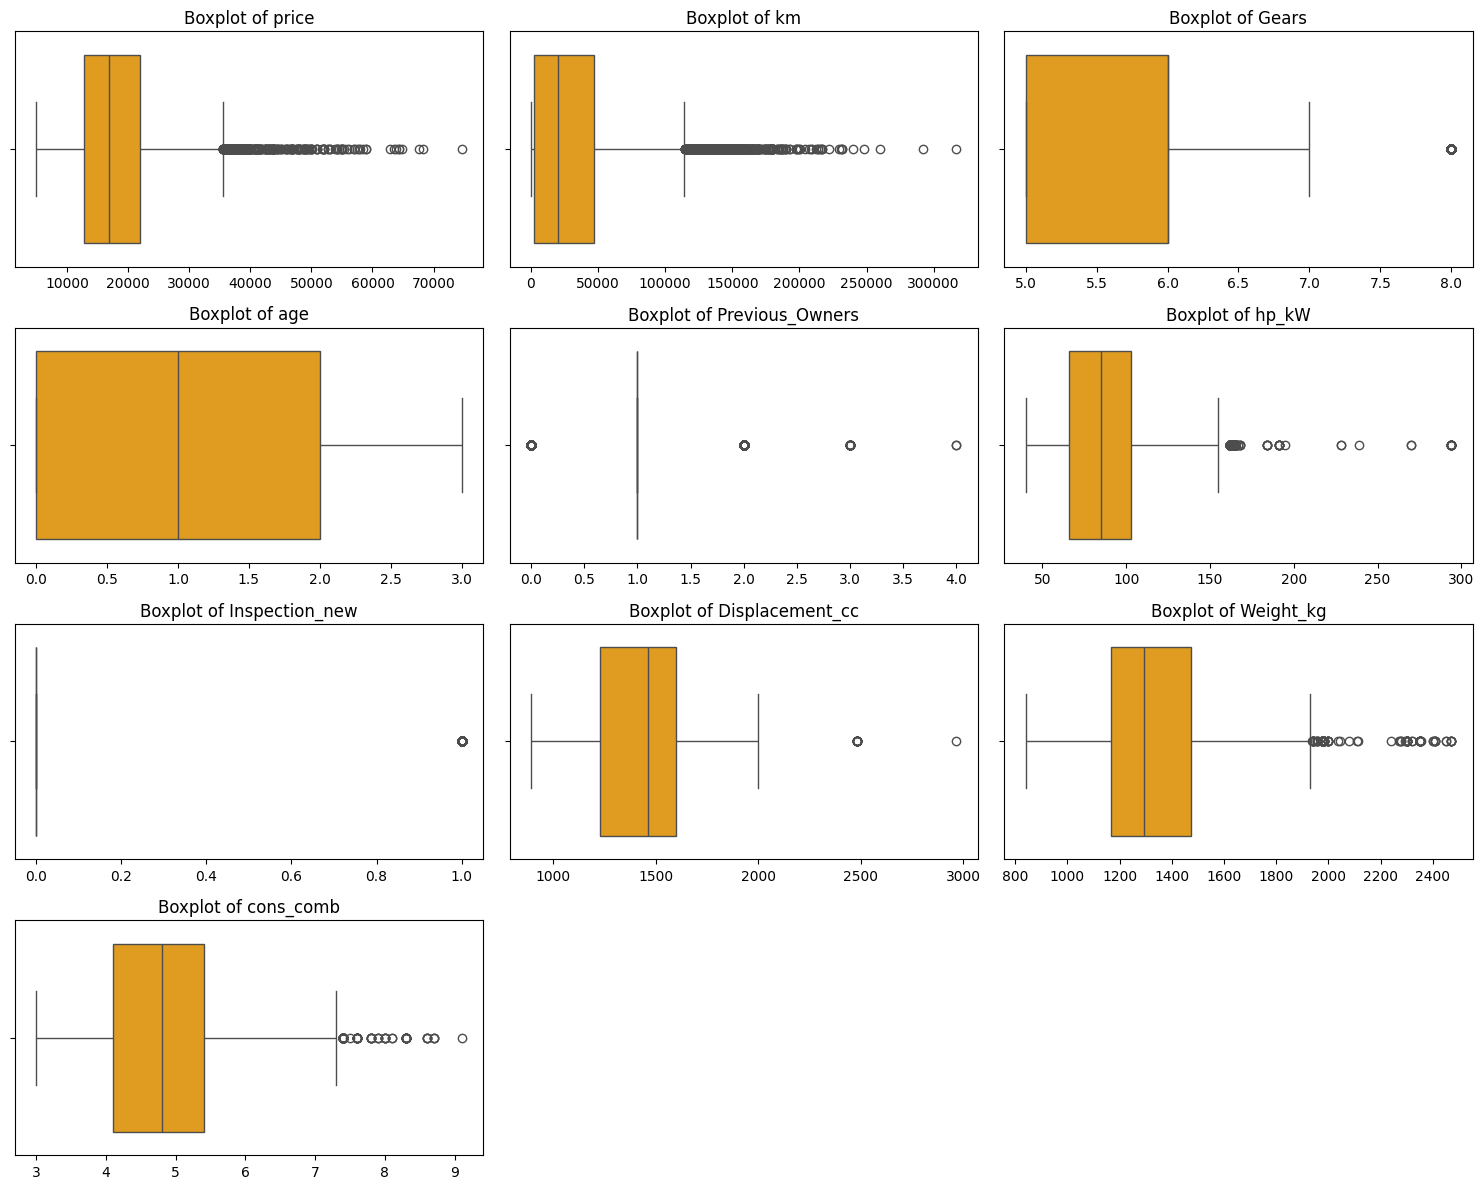

,Lower Bound,Upper Bound,Outliers Count,Percentage
price,-725.00,35475.00,479.0,3.01
km,-65548.75,114369.25,689.0,4.33
Gears,3.50,7.50,225.0,1.41
age,-3.00,5.00,0.0,0.00
Previous_Owners,1.00,1.00,1757.0,11.04
hp_kW,10.50,158.50,361.0,2.27
Inspection_new,0.00,0.00,3932.0,24.71
Displacement_cc,675.50,2151.50,21.0,0.13
Weight_kg,704.50,1932.50,87.0,0.55
cons_comb,2.15,7.35,125.0,0.79


In [13]:
# Outliers present in each column
# Calculate IQR for each numerical column
outliers_summary = {}
plt.figure(figsize=(15, 12))

for i, col in enumerate(numerical_cols, 1):
    # Plotting boxplot
    plt.subplot(4, 3, i)
    sns.boxplot(x=df[col], color='orange')
    plt.title(f'Boxplot of {col}')
    plt.xlabel('')

    # IQR calculation
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count outliers
    outliers_count = df[(df[col] < lower_bound) | (df[col] > upper_bound)].shape[0]
    outliers_summary[col] = {
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outliers Count': outliers_count,
        'Percentage': round((outliers_count / len(df)) * 100, 2)
    }

plt.tight_layout()
plt.show()

# Display outlier summary table
outliers_df = pd.DataFrame(outliers_summary).T
display(outliers_df)

#### **2.3.2** <font color =red> [3 marks] </font>
Handle the outliers suitably.

In [14]:
# Handle outliers


# Identify the continuous numerical columns to handle
continuous_cols = ['km', 'hp_kW', 'Displacement_cc', 'Weight_kg', 'cons_comb']

print("Summary of extreme values before capping:")
display(df[continuous_cols].describe(percentiles=[0.01, 0.99]))

# Apply capping
for col in continuous_cols:
    lower_limit = df[col].quantile(0.01)
    upper_limit = df[col].quantile(0.99)
    df[col] = np.clip(df[col], lower_limit, upper_limit)

print("\nSummary of values after capping at 1st and 99th percentiles:")
display(df[continuous_cols].describe(percentiles=[0.01, 0.99]))

Summary of extreme values before capping:


,km,hp_kW,Displacement_cc,Weight_kg,cons_comb
count,15915.000000,15915.000000,15915.000000,15915.000000,15915.000000
mean,32089.995708,88.499340,1428.661891,1337.700534,4.832124
std,36977.214964,26.674341,275.804272,199.682385,0.867530
min,0.000000,40.000000,890.000000,840.000000,3.000000
1%,1.000000,51.000000,898.000000,1063.000000,3.300000
50%,20413.000000,85.000000,1461.000000,1295.000000,4.800000
99%,154987.400000,165.000000,1997.000000,1845.000000,7.100000
max,317000.000000,294.000000,2967.000000,2471.000000,9.100000



Summary of values after capping at 1st and 99th percentiles:


,km,hp_kW,Displacement_cc,Weight_kg,cons_comb
count,15915.000000,15915.000000,15915.000000,15915.000000,15915.000000
mean,31860.385592,88.309394,1427.984229,1335.857619,4.828762
std,36042.845809,25.699541,273.758577,191.893484,0.848981
min,1.000000,51.000000,898.000000,1063.000000,3.300000
1%,1.000000,51.000000,898.000000,1063.000000,3.300000
50%,20413.000000,85.000000,1461.000000,1295.000000,4.800000
99%,154976.564000,165.000000,1997.000000,1845.000000,7.100000
max,154987.400000,165.000000,1997.000000,1845.000000,7.100000


### **2.4 Feature Engineering** <font color = red> [11 marks] </font>

#### **2.4.1**
Fix any redundant columns and create new ones if needed.

In [15]:
# Fix/create columns as needed
# Since we are predicting log_price, we must exclude the original 'price' column from our training features.
if 'price' in df.columns:
    df_clean = df.drop(columns=['price'])
else:
    df_clean = df.copy()

print("Columns prepared for feature engineering:")
print(df_clean.columns.tolist())

Columns prepared for feature engineering:
['make_model', 'body_type', 'vat', 'km', 'Type', 'Fuel', 'Gears', 'Comfort_Convenience', 'Entertainment_Media', 'Extras', 'Safety_Security', 'age', 'Previous_Owners', 'hp_kW', 'Inspection_new', 'Paint_Type', 'Upholstery_type', 'Gearing_Type', 'Displacement_cc', 'Weight_kg', 'Drive_chain', 'cons_comb', 'log_price']


#### **2.4.2** <font color =red> [4 marks] </font>
Analysis and feature engineering on `['Comfort_Convenience', 'Entertainment_Media', 'Extras', 'Safety_Security']`.

These columns contains lists of features present. Decide on how to include these features in the predictors.

In [16]:
# Check unique values in each feature spec column

import ast

def get_unique_items(series):
    unique_items = set()
    for row in series.dropna():
        # Features are represented as a string list, e.g. "['Air conditioning', 'Cruise control']"
        # Let's cleanly parse them using ast.literal_eval or string splitting
        try:
            items = ast.literal_eval(row)
            if isinstance(items, list):
                unique_items.update([item.strip() for item in items])
        except:
            # Fallback if it is a comma-separated string
            items = row.replace('[', '').replace(']', '').replace("'", "").split(',')
            unique_items.update([item.strip() for item in items if item.strip()])
    return sorted(list(unique_items))

for col in spec_cols:
    unique_list = get_unique_items(df_clean[col])
    print(f"{col} has {len(unique_list)} unique features. First 10 examples:")
    print(unique_list[:10])
    print("-" * 50)

Comfort_Convenience has 38 unique features. First 10 examples:
['Air conditioning', 'Air suspension', 'Armrest', 'Automatic climate control', 'Auxiliary heating', 'Cruise control', 'Electric Starter', 'Electric tailgate', 'Electrical side mirrors', 'Electrically adjustable seats']
--------------------------------------------------
Entertainment_Media has 10 unique features. First 10 examples:
['Bluetooth', 'CD player', 'Digital radio', 'Hands-free equipment', 'MP3', 'On-board computer', 'Radio', 'Sound system', 'Television', 'USB']
--------------------------------------------------
Extras has 17 unique features. First 10 examples:
['Alloy wheels', 'Cab or rented Car', 'Catalytic Converter', 'Handicapped enabled', 'Right hand drive', 'Roof rack', 'Shift paddles', 'Ski bag', 'Sliding door', 'Sport package']
--------------------------------------------------
Safety_Security has 29 unique features. First 10 examples:
['ABS', 'Adaptive Cruise Control', 'Adaptive headlights', 'Alarm system',

Out of these features, we will check the ones which are present in most of the cars or are absent from most of the cars. These kinds of features can be removed as they just increase the dimensionality without explaining the variance.

In [19]:
# Drop features from df
import ast
from collections import Counter

# Ensure we reset df_clean properly from df (excluding 'price') to avoid KeyError
if 'price' in df.columns:
    df_clean = df.drop(columns=['price'])
else:
    df_clean = df.copy()

# Calculate frequency of each item across the dataset
feature_counts = Counter()
total_rows = len(df_clean)

for col in spec_cols:
    for row in df_clean[col].dropna():
        try:
            items = ast.literal_eval(row)
            if isinstance(items, list):
                for item in items:
                    feature_counts[f"{col}_{item.strip()}"] += 1
        except:
            items = row.replace('[', '').replace(']', '').replace("'", "").split(',')
            for item in items:
                if item.strip():
                    feature_counts[f"{col}_{item.strip()}"] += 1

# Identify features to keep based on threshold (between 5% and 95% frequency)
lower_threshold = 0.05 * total_rows
upper_threshold = 0.95 * total_rows

features_to_keep = []
features_to_drop = []

for feature, count in feature_counts.items():
    if lower_threshold <= count <= upper_threshold:
        features_to_keep.append(feature)
    else:
        features_to_drop.append(feature)

print(f"Total extracted features: {len(feature_counts)}")
print(f"Features kept (between 5% and 95% variance): {len(features_to_keep)}")
print(f"Features dropped (too rare or too common): {len(features_to_drop)}")

# Create binary columns for the kept features
for col in spec_cols:
    for feature_name in features_to_keep:
        if feature_name.startswith(col + "_"):
            real_feature = feature_name.replace(col + "_", "")
            df_clean[feature_name] = df_clean[col].apply(lambda x: 1 if real_feature in str(x) else 0)

# Now drop the original nested list columns from df_clean
df_clean = df_clean.drop(columns=spec_cols)
print("Original nested specification columns dropped. Cleaned dataframe shape:", df_clean.shape)

Total extracted features: 94
Features kept (between 5% and 95% variance): 71
Features dropped (too rare or too common): 23
Original nested specification columns dropped. Cleaned dataframe shape: (15915, 90)


#### **2.4.3** <font color =red> [3 marks] </font>
Perform feature encoding.

In [20]:
# Encode features
# Identify categorical columns currently present in our clean dataframe
categorical_to_encode = [col for col in categorical_predictors if col in df_clean.columns]

# Apply One-Hot Encoding to the categorical features using pandas.get_dummies
# Setting drop_first=True prevents perfect multicollinearity (the dummy variable trap)
df_encoded = pd.get_dummies(df_clean, columns=categorical_to_encode, drop_first=True, dtype=int)

print("Original clean dataframe shape:", df_clean.shape)
print("Encoded dataframe shape (including dummy columns):", df_encoded.shape)
print("\nFirst few columns of the encoded dataframe:")
display(df_encoded.head())

Original clean dataframe shape: (15915, 90)
Encoded dataframe shape (including dummy columns): (15915, 107)

First few columns of the encoded dataframe:


,km,Gears,age,Previous_Owners,hp_kW,Inspection_new,Displacement_cc,Weight_kg,cons_comb,log_price,...,Type_Used,Fuel_Benzine,Fuel_Diesel,Paint_Type_Perl effect,Paint_Type_Uni/basic,Upholstery_type_Part/Full Leather,Gearing_Type_Manual,Gearing_Type_Semi-automatic,Drive_chain_front,Drive_chain_rear
0,56013.0,7.0,3.0,2.0,66.0,1,1422.0,1220.0,3.8,9.665865,...,1,0,1,0,0,0,0,0,1,0
1,80000.0,7.0,2.0,1.0,141.0,0,1798.0,1255.0,5.6,9.581904,...,1,1,0,0,0,0,0,0,1,0
2,83450.0,7.0,3.0,1.0,85.0,0,1598.0,1135.0,3.8,9.591513,...,1,0,1,0,0,0,0,0,1,0
3,73000.0,6.0,3.0,1.0,66.0,0,1422.0,1195.0,3.8,9.581904,...,1,0,1,0,0,0,0,0,1,0
4,16200.0,7.0,3.0,1.0,66.0,1,1422.0,1135.0,4.1,9.728539,...,1,0,1,0,0,0,0,0,1,0


#### **2.4.4** <font color =red> [2 marks] </font>
Split the data into training and testing sets.

In [21]:
# Split the dataset
X = df_encoded.drop(columns=['log_price'])
y = df_encoded['log_price']

# Split the data into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")
print(f"Training target shape: {y_train.shape}")
print(f"Testing target shape: {y_test.shape}")

Training features shape: (12732, 106)
Testing features shape: (3183, 106)
Training target shape: (12732,)
Testing target shape: (3183,)


#### **2.4.5** <font color =red> [2 marks] </font>
Scale the features.

In [22]:

# Scale features
columns_to_scale = ['km', 'Gears', 'age', 'Previous_Owners', 'hp_kW', 'Displacement_cc', 'Weight_kg', 'cons_comb']

# Initialize the StandardScaler
scaler = StandardScaler()

# Copy the sets to avoid SettingWithCopy warnings
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit on training data and transform both training and testing data
X_train_scaled[columns_to_scale] = scaler.fit_transform(X_train[columns_to_scale])
X_test_scaled[columns_to_scale] = scaler.transform(X_test[columns_to_scale])

print("Feature scaling completed successfully.")
print("Mean of scaled 'km' in training set:", round(X_train_scaled['km'].mean(), 4))
print("Std of scaled 'km' in training set:", round(X_train_scaled['km'].std(), 4))


Feature scaling completed successfully.
Mean of scaled 'km' in training set: 0.0
Std of scaled 'km' in training set: 1.0


## **3 Linear Regression Models** <font color =red> [35 marks] </font>


### **3.1 Baseline Linear Regression Model** <font color =red> [10 marks] </font>

#### **3.1.1** <font color =red> [5 marks] </font>
Build and fit a basic linear regression model. Perform evaluation using suitable metrics.

In [ ]:
# Initialise and train model


In [24]:
# Initialise and train model

base_lr = LinearRegression()

# Train the model on the scaled training dataset
base_lr.fit(X_train_scaled, y_train)

# Make predictions on both train and test sets
y_train_pred = base_lr.predict(X_train_scaled)
y_test_pred = base_lr.predict(X_test_scaled)

print("Baseline Linear Regression model trained successfully.")

Baseline Linear Regression model trained successfully.


In [25]:

# Evaluate the model's performance
# Calculate metrics for the training set
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

# Calculate metrics for the test set
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

print("--- Baseline Linear Regression Evaluation ---")
print(f"Training Set:")
print(f"  MAE:  {train_mae:.4f}")
print(f"  RMSE: {train_rmse:.4f}")
print(f"  R2:   {train_r2:.4f}")
print("\nTesting Set:")
print(f"  MAE:  {test_mae:.4f}")
print(f"  RMSE: {test_rmse:.4f}")
print(f"  R2:   {test_r2:.4f}")


--- Baseline Linear Regression Evaluation ---
Training Set:
  MAE:  0.0786
  RMSE: 0.1068
  R2:   0.9279

Testing Set:
  MAE:  0.0777
  RMSE: 0.1032
  R2:   0.9333


#### **3.1.2** <font color =red> [5 marks] </font>
Analyse residuals and check other assumptions of linear regression.

Check for linearity by analysing residuals vs predicted values

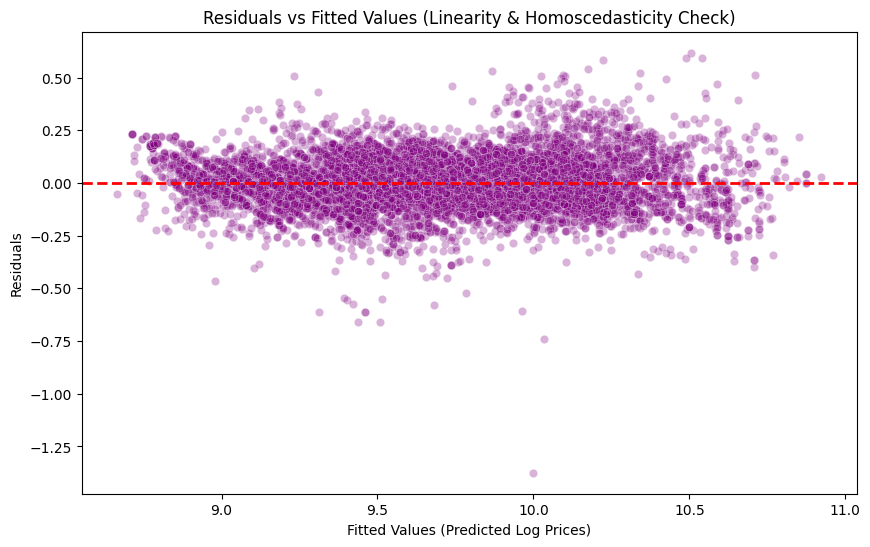

In [26]:
# Linearity check: Plot residuals vs fitted values

residuals = y_train - y_train_pred

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_train_pred, y=residuals, alpha=0.3, color='purple')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.title('Residuals vs Fitted Values (Linearity & Homoscedasticity Check)')
plt.xlabel('Fitted Values (Predicted Log Prices)')
plt.ylabel('Residuals')
plt.show()


Check normality in residual distribution

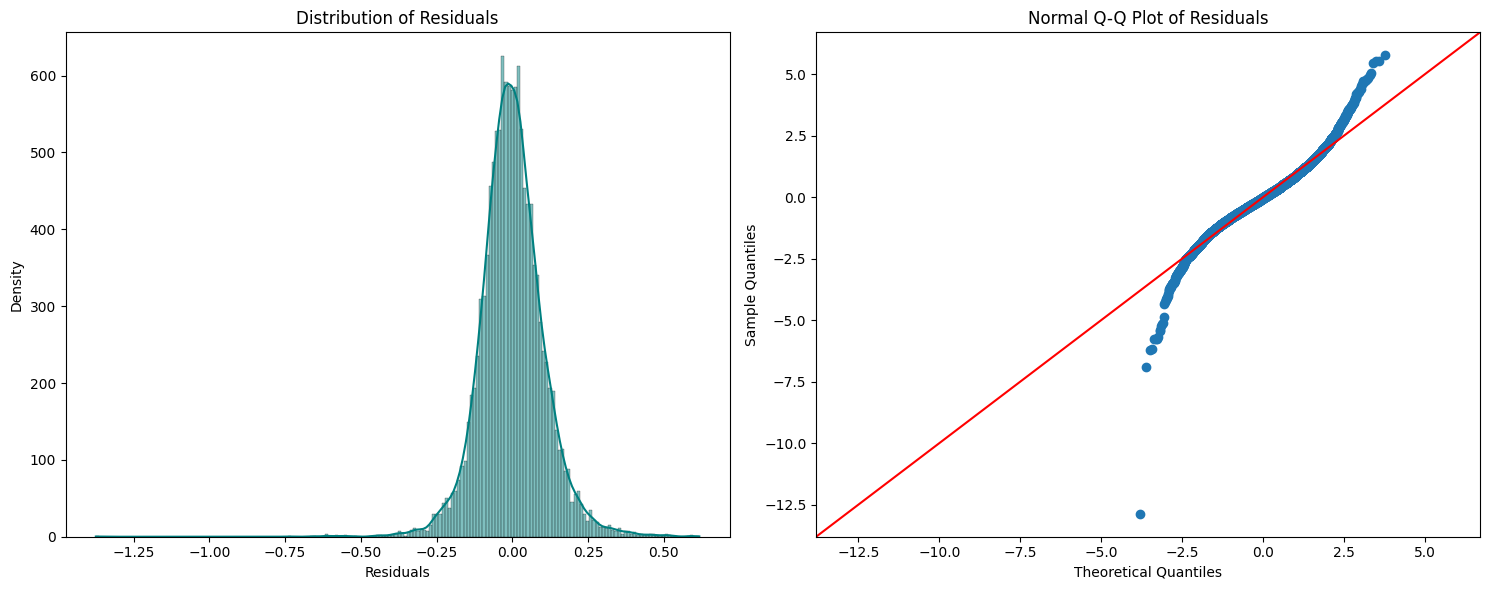

In [27]:
# Check the normality of residuals by plotting their distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Histogram / Density plot of residuals
sns.histplot(residuals, kde=True, color='teal', ax=axes[0])
axes[0].set_title('Distribution of Residuals')
axes[0].set_xlabel('Residuals')
axes[0].set_ylabel('Density')

# Plot 2: Q-Q Plot
sm.qqplot(residuals, line='45', fit=True, ax=axes[1])
axes[1].set_title('Normal Q-Q Plot of Residuals')

plt.tight_layout()
plt.show()


Check multicollinearity using Variance Inflation Factor (VIF) and handle features with high VIF.

In [28]:
# Check for multicollinearity and handle
from statsmodels.stats.outliers_influence import variance_inflation_factor

# We will calculate VIF for numerical continuous variables and key indicators in X_train_scaled
# To make calculation faster and clean, let's look at the continuous features and a subset of encoders first
features_for_vif = ['km', 'Gears', 'age', 'Previous_Owners', 'hp_kW', 'Displacement_cc', 'Weight_kg', 'cons_comb']

X_vif = X_train_scaled[features_for_vif]

vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

display(vif_data.sort_values(by="VIF", ascending=False))


,feature,VIF
4,hp_kW,2.968092
2,age,2.843991
0,km,2.683118
6,Weight_kg,2.053982
5,Displacement_cc,1.979663
7,cons_comb,1.484936
1,Gears,1.344668
3,Previous_Owners,1.143280


### **3.2 Ridge Regression Implementation** <font color =red> [10 marks] </font>

#### **3.2.1** <font color =red> [2 marks] </font>
Define a list of random alpha values

In [29]:
# List of alphas to tune for Ridge regularisation

alphas = [0.01, 0.1, 1.0, 10.0, 50.0, 100.0, 200.0, 500.0, 1000.0]
print("Ridge alphas initialized:", alphas)


Ridge alphas initialized: [0.01, 0.1, 1.0, 10.0, 50.0, 100.0, 200.0, 500.0, 1000.0]


#### **3.2.2** <font color =red> [4 marks] </font>
Apply Ridge Regularisation and find the best value of alpha from the list

In [30]:
# Applying Ridge regression
ridge_model = Ridge()

# Set up 5-fold cross-validation
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Configure GridSearchCV using negative Mean Absolute Error as the metric
ridge_cv = GridSearchCV(
    estimator=ridge_model,
    param_grid={'alpha': alphas},
    scoring='neg_mean_absolute_error',
    cv=kfold,
    return_train_score=True
)

# Fit on scaled training data
ridge_cv.fit(X_train_scaled, y_train)

print("Ridge Grid Search completed.")


Ridge Grid Search completed.


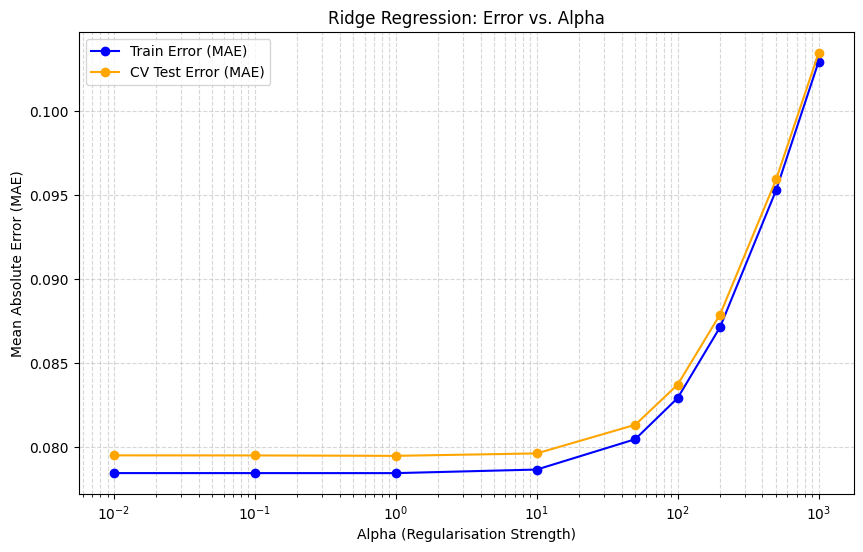

In [31]:
# Plot train and test scores against alpha
plt.figure(figsize=(10, 6))
plt.plot(alphas, -ridge_cv.cv_results_['mean_train_score'], label='Train Error (MAE)', marker='o', color='blue')
plt.plot(alphas, -ridge_cv.cv_results_['mean_test_score'], label='CV Test Error (MAE)', marker='o', color='orange')
plt.xscale('log')
plt.xlabel('Alpha (Regularisation Strength)')
plt.ylabel('Mean Absolute Error (MAE)')
plt.title('Ridge Regression: Error vs. Alpha')
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.show()


Find the best alpha value.

In [32]:
# Best alpha value
best_alpha = ridge_cv.best_params_['alpha']
print("Best alpha value from the initial list:", best_alpha)

# Best score (negative MAE)
best_score = ridge_cv.best_score_
print("Best Negative MAE score:", round(best_score, 4))
print("Equivalent MAE:", round(-best_score, 4))


Best alpha value from the initial list: 1.0
Best Negative MAE score: -0.0795
Equivalent MAE: 0.0795


We will get some best value of alpha above. This however is not the most accurate value but the best value from the given list. Now we have a rough estimate of the range that best alpha falls in. Let us do another iteration over the values in a smaller range.

#### **3.2.3** <font color =red> [4 marks] </font>
Fine tune by taking a closer range of alpha based on the previous result.

In [ ]:
# Take a smaller range of alpha to test




In [33]:
# Define a narrower, finer range of alpha values centered around 1.0
fine_alphas = np.linspace(0.1, 10.0, 50)
print("Fine-tuning Ridge alphas range:", fine_alphas)


Fine-tuning Ridge alphas range: [ 0.1         0.30204082  0.50408163  0.70612245  0.90816327  1.11020408
  1.3122449   1.51428571  1.71632653  1.91836735  2.12040816  2.32244898
  2.5244898   2.72653061  2.92857143  3.13061224  3.33265306  3.53469388
  3.73673469  3.93877551  4.14081633  4.34285714  4.54489796  4.74693878
  4.94897959  5.15102041  5.35306122  5.55510204  5.75714286  5.95918367
  6.16122449  6.36326531  6.56530612  6.76734694  6.96938776  7.17142857
  7.37346939  7.5755102   7.77755102  7.97959184  8.18163265  8.38367347
  8.58571429  8.7877551   8.98979592  9.19183673  9.39387755  9.59591837
  9.79795918 10.        ]


In [34]:
# Perform fine-tuned GridSearchCV for Ridge Regression
ridge_fine_cv = GridSearchCV(
    estimator=Ridge(),
    param_grid={'alpha': fine_alphas},
    scoring='neg_mean_absolute_error',
    cv=kfold,
    return_train_score=True
)

# Fit the model on our scaled training set
ridge_fine_cv.fit(X_train_scaled, y_train)
print("Ridge fine-tuning Grid Search completed.")


Ridge fine-tuning Grid Search completed.


In [ ]:
# Applying Ridge regression





Plot the error-alpha graph again and find the actual optimal value for alpha.

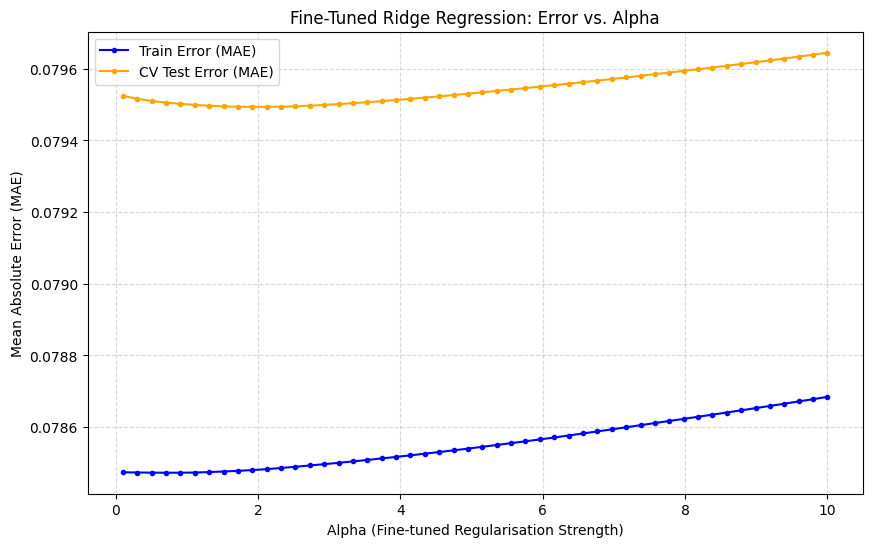

Optimal Alpha from fine-tuning: 1.9184
Best Negative MAE from fine-tuning: -0.0795
Equivalent MAE: 0.0795


In [35]:
# Plot train and test scores against the finer alpha values
plt.figure(figsize=(10, 6))
plt.plot(fine_alphas, -ridge_fine_cv.cv_results_['mean_train_score'], label='Train Error (MAE)', marker='.', color='blue')
plt.plot(fine_alphas, -ridge_fine_cv.cv_results_['mean_test_score'], label='CV Test Error (MAE)', marker='.', color='orange')
plt.xlabel('Alpha (Fine-tuned Regularisation Strength)')
plt.ylabel('Mean Absolute Error (MAE)')
plt.title('Fine-Tuned Ridge Regression: Error vs. Alpha')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Identify the final optimal alpha and score
optimal_ridge_alpha = ridge_fine_cv.best_params_['alpha']
best_fine_score = ridge_fine_cv.best_score_

print(f"Optimal Alpha from fine-tuning: {optimal_ridge_alpha:.4f}")
print(f"Best Negative MAE from fine-tuning: {best_fine_score:.4f}")
print(f"Equivalent MAE: {-best_fine_score:.4f}")


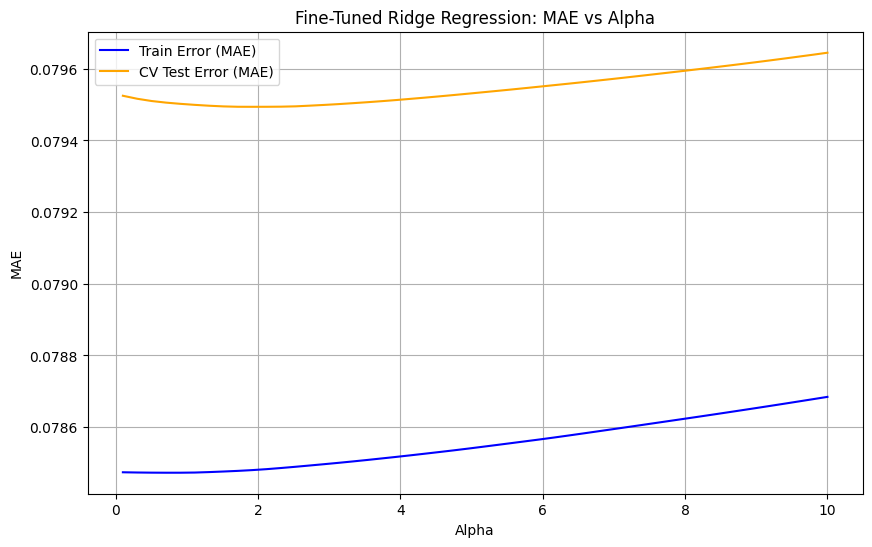

Best fine-tuned alpha: 1.9184
Best CV score (Neg MAE): -0.0795
Best CV score (MAE): 0.0795


In [36]:
# Plot train and test scores against alpha
plt.figure(figsize=(10, 6))
plt.plot(fine_alphas, -ridge_fine_cv.cv_results_['mean_train_score'], label='Train Error (MAE)', color='blue')
plt.plot(fine_alphas, -ridge_fine_cv.cv_results_['mean_test_score'], label='CV Test Error (MAE)', color='orange')
plt.xlabel('Alpha')
plt.ylabel('MAE')
plt.title('Fine-Tuned Ridge Regression: MAE vs Alpha')
plt.legend()
plt.grid(True)
plt.show()

# Best alpha value
optimal_ridge_alpha = ridge_fine_cv.best_params_['alpha']
print("Best fine-tuned alpha:", round(optimal_ridge_alpha, 4))

# Best score (negative MAE)
best_fine_score = ridge_fine_cv.best_score_
print("Best CV score (Neg MAE):", round(best_fine_score, 4))
print("Best CV score (MAE):", round(-best_fine_score, 4))


In [37]:
# Set best alpha for Ridge regression
best_ridge_alpha = 1.9184

# Fit the Ridge model to get the coefficients of the fitted model
ridge_final = Ridge(alpha=best_ridge_alpha)
ridge_final.fit(X_train_scaled, y_train)

print(f"Final Ridge regression model fitted with alpha = {best_ridge_alpha}")

Final Ridge regression model fitted with alpha = 1.9184


In [38]:
# Show the coefficients for each feature
ridge_coefs = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': ridge_final.coef_
})

# Sort coefficients by absolute magnitude for better analysis
ridge_coefs['Abs_Coefficient'] = ridge_coefs['Coefficient'].abs()
ridge_coefs_sorted = ridge_coefs.sort_values(by='Abs_Coefficient', ascending=False).drop(columns=['Abs_Coefficient'])

print("Top 20 most influential features in final Ridge Model:")
display(ridge_coefs_sorted.head(20))


Top 20 most influential features in final Ridge Model:


,Feature,Coefficient
83,make_model_Opel Corsa,-0.442839
85,make_model_Renault Clio,-0.401595
86,make_model_Renault Duster,-0.366447
82,make_model_Opel Astra,-0.224843
87,make_model_Renault Espace,0.147741
102,Gearing_Type_Manual,-0.112360
88,body_type_Convertible,-0.110753
103,Gearing_Type_Semi-automatic,0.104988
4,hp_kW,0.103524
2,age,-0.102380


In [39]:
# Evaluate the Ridge model on the test data
y_test_pred_ridge = ridge_final.predict(X_test_scaled)

# Calculate evaluation metrics for the Ridge model on the test set
ridge_test_mae = mean_absolute_error(y_test, y_test_pred_ridge)
ridge_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_ridge))
ridge_test_r2 = r2_score(y_test, y_test_pred_ridge)

print("--- Final Ridge Regression Evaluation on Test Set ---")
print(f"  MAE:  {ridge_test_mae:.4f}")
print(f"  RMSE: {ridge_test_rmse:.4f}")
print(f"  R2:   {ridge_test_r2:.4f}")


--- Final Ridge Regression Evaluation on Test Set ---
  MAE:  0.0777
  RMSE: 0.1032
  R2:   0.9334


### **3.3 Lasso Regression Implementation** <font color =red> [10 marks] </font>

#### **3.3.1** <font color =red> [2 marks] </font>
Define a list of random alpha values

In [40]:
# List of alphas to tune for Lasso regularisation
lasso_alphas = [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1.0, 10.0, 50.0, 100.0]
print("Lasso alphas initialized:", lasso_alphas)

Lasso alphas initialized: [1e-05, 0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 50.0, 100.0]


#### **3.3.2** <font color =red> [4 marks] </font>
Apply Ridge Regularisation and find the best value of alpha from the list

In [41]:
# Initialise Lasso regression model
lasso_model = Lasso(max_iter=5000, random_state=42)

# Set up GridSearchCV with 5-fold cross-validation and Negative MAE scoring
lasso_cv = GridSearchCV(
    estimator=lasso_model,
    param_grid={'alpha': lasso_alphas},
    scoring='neg_mean_absolute_error',
    cv=kfold,
    return_train_score=True
)

# Fit on the scaled training dataset
lasso_cv.fit(X_train_scaled, y_train)
print("Lasso Grid Search completed.")

Lasso Grid Search completed.


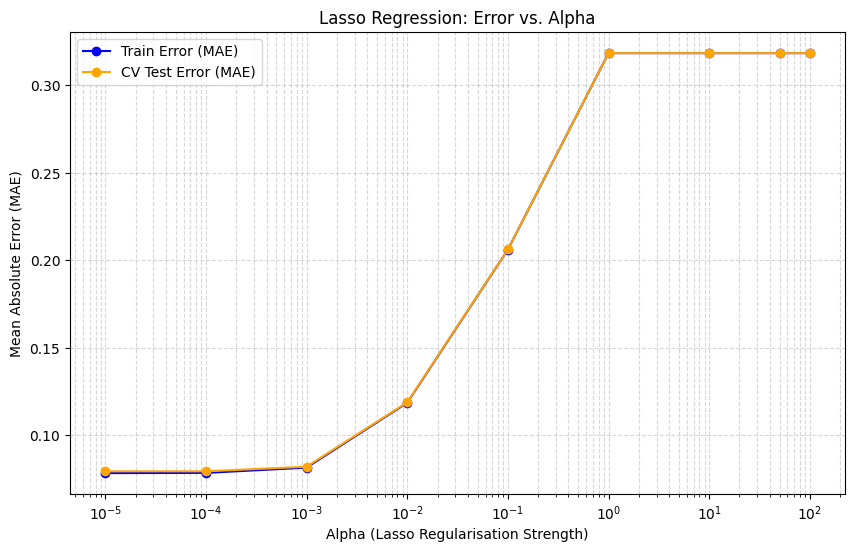

In [42]:
# Plot train and test scores against alpha for Lasso Regression
plt.figure(figsize=(10, 6))
plt.plot(lasso_alphas, -lasso_cv.cv_results_['mean_train_score'], label='Train Error (MAE)', marker='o', color='blue')
plt.plot(lasso_alphas, -lasso_cv.cv_results_['mean_test_score'], label='CV Test Error (MAE)', marker='o', color='orange')
plt.xscale('log')
plt.xlabel('Alpha (Lasso Regularisation Strength)')
plt.ylabel('Mean Absolute Error (MAE)')
plt.title('Lasso Regression: Error vs. Alpha')
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.show()

In [43]:
# Best alpha value from the initial Lasso list
best_lasso_alpha = lasso_cv.best_params_['alpha']
print("Best alpha value from the initial list:", best_lasso_alpha)

# Best score (negative MAE)
best_lasso_score = lasso_cv.best_score_
print("Best Negative MAE score:", round(best_lasso_score, 4))
print("Equivalent MAE:", round(-best_lasso_score, 4))

Best alpha value from the initial list: 0.0001
Best Negative MAE score: -0.0795
Equivalent MAE: 0.0795


#### **3.3.3** <font color =red> [4 marks] </font>
Fine tune by taking a closer range of alpha based on the previous result.

In [44]:
# List of alphas to tune for Lasso regularization
fine_lasso_alphas = np.linspace(1e-6, 1e-3, 50)
print("Fine-tuning Lasso alphas initialized:", fine_lasso_alphas)

Fine-tuning Lasso alphas initialized: [1.00000000e-06 2.13877551e-05 4.17755102e-05 6.21632653e-05
 8.25510204e-05 1.02938776e-04 1.23326531e-04 1.43714286e-04
 1.64102041e-04 1.84489796e-04 2.04877551e-04 2.25265306e-04
 2.45653061e-04 2.66040816e-04 2.86428571e-04 3.06816327e-04
 3.27204082e-04 3.47591837e-04 3.67979592e-04 3.88367347e-04
 4.08755102e-04 4.29142857e-04 4.49530612e-04 4.69918367e-04
 4.90306122e-04 5.10693878e-04 5.31081633e-04 5.51469388e-04
 5.71857143e-04 5.92244898e-04 6.12632653e-04 6.33020408e-04
 6.53408163e-04 6.73795918e-04 6.94183673e-04 7.14571429e-04
 7.34959184e-04 7.55346939e-04 7.75734694e-04 7.96122449e-04
 8.16510204e-04 8.36897959e-04 8.57285714e-04 8.77673469e-04
 8.98061224e-04 9.18448980e-04 9.38836735e-04 9.59224490e-04
 9.79612245e-04 1.00000000e-03]


In [45]:
# Tuning Lasso hyperparameters
lasso_fine_cv = GridSearchCV(
    estimator=Lasso(max_iter=10000, random_state=42),
    param_grid={'alpha': fine_lasso_alphas},
    scoring='neg_mean_absolute_error',
    cv=kfold,
    return_train_score=True
)

# Fit on the scaled training dataset
lasso_fine_cv.fit(X_train_scaled, y_train)
print("Lasso fine-tuning Grid Search completed.")

Lasso fine-tuning Grid Search completed.


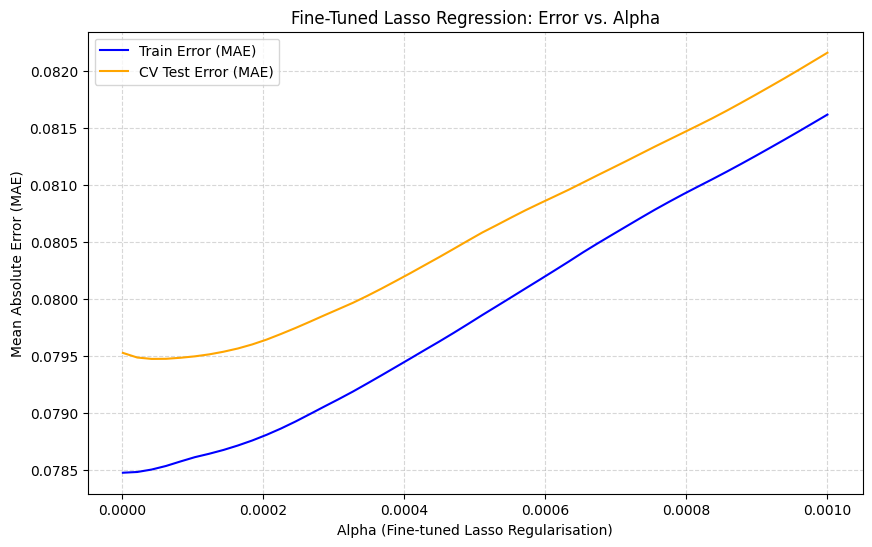

In [47]:
# Plot train and test scores against alpha
plt.figure(figsize=(10, 6))
plt.plot(fine_lasso_alphas, -lasso_fine_cv.cv_results_['mean_train_score'], label='Train Error (MAE)', color='blue')
plt.plot(fine_lasso_alphas, -lasso_fine_cv.cv_results_['mean_test_score'], label='CV Test Error (MAE)', color='orange')
plt.xlabel('Alpha (Fine-tuned Lasso Regularisation)')
plt.ylabel('Mean Absolute Error (MAE)')
plt.title('Fine-Tuned Lasso Regression: Error vs. Alpha')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [48]:
# Best alpha value
optimal_lasso_alpha = lasso_fine_cv.best_params_['alpha']
print("Best fine-tuned Lasso alpha:", round(optimal_lasso_alpha, 6))

# Best score (negative MAE)
best_lasso_fine_score = lasso_fine_cv.best_score_
print("Best CV score (Neg MAE):", round(best_lasso_fine_score, 4))
print("Best CV score (MAE):", round(-best_lasso_fine_score, 4))

Best fine-tuned Lasso alpha: 4.2e-05
Best CV score (Neg MAE): -0.0795
Best CV score (MAE): 0.0795


In [49]:
# Set best alpha for Lasso regression
best_lasso_alpha = 4.177551020408163e-05

# Fit the Lasso model on scaled training data
lasso_final = Lasso(alpha=best_lasso_alpha, max_iter=10000, random_state=42)
lasso_final.fit(X_train_scaled, y_train)

# Get the coefficients of the fitted model
print(f"Final Lasso regression model fitted successfully with alpha = {best_lasso_alpha:.6f}")

Final Lasso regression model fitted successfully with alpha = 0.000042


In [50]:
# Check the coefficients for each feature
lasso_coefs = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lasso_final.coef_
})

# Calculate absolute values for sorting
lasso_coefs['Abs_Coefficient'] = lasso_coefs['Coefficient'].abs()
lasso_coefs_sorted = lasso_coefs.sort_values(by='Abs_Coefficient', ascending=False).drop(columns=['Abs_Coefficient'])

# Filter out eliminated features (where coefficient is exactly 0)
eliminated_features = lasso_coefs_sorted[lasso_coefs_sorted['Coefficient'] == 0]
active_features = lasso_coefs_sorted[lasso_coefs_sorted['Coefficient'] != 0]

print(f"Total features: {len(lasso_coefs)}")
print(f"Features retained (non-zero): {len(active_features)}")
print(f"Features eliminated (exactly zero): {len(eliminated_features)}")

print("\nTop 20 most influential features in the final Lasso Model:")
display(active_features.head(20))

Total features: 106
Features retained (non-zero): 101
Features eliminated (exactly zero): 5

Top 20 most influential features in the final Lasso Model:


,Feature,Coefficient
83,make_model_Opel Corsa,-0.445215
86,make_model_Renault Duster,-0.416190
85,make_model_Renault Clio,-0.402789
82,make_model_Opel Astra,-0.226356
87,make_model_Renault Espace,0.144795
102,Gearing_Type_Manual,-0.112911
103,Gearing_Type_Semi-automatic,0.103347
2,age,-0.102761
4,hp_kW,0.102743
81,make_model_Audi A3,0.090612


In [ ]:
# Evaluate the Lasso model on the test data



In [52]:
# Evaluate the Lasso model on the test data
y_test_pred_lasso = lasso_final.predict(X_test_scaled)

# Calculate evaluation metrics for Lasso
lasso_test_mae = mean_absolute_error(y_test, y_test_pred_lasso)
lasso_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_lasso))
lasso_test_r2 = r2_score(y_test, y_test_pred_lasso)

print("--- Final Lasso Regression Evaluation on Test Set ---")
print(f"  MAE:  {lasso_test_mae:.4f}")
print(f"  RMSE: {lasso_test_rmse:.4f}")
print(f"  R2:   {lasso_test_r2:.4f}")

--- Final Lasso Regression Evaluation on Test Set ---
  MAE:  0.0776
  RMSE: 0.1030
  R2:   0.9336


### **3.4 Regularisation Comparison & Analysis** <font color =red> [5 marks] </font>

#### **3.4.1** <font color =red> [2 marks] </font>
Compare the evaluation metrics for each model.

In [ ]:
# Compare metrics for each model




In [53]:
# Compare metrics for each model
metrics_comparison = pd.DataFrame({
    'Model': ['Baseline Linear Regression', 'Fine-Tuned Ridge', 'Fine-Tuned Lasso'],
    'Test MAE': [test_mae, ridge_test_mae, lasso_test_mae],
    'Test RMSE': [test_rmse, ridge_test_rmse, lasso_test_rmse],
    'Test R2': [test_r2, ridge_test_r2, lasso_test_r2]
})

display(metrics_comparison.round(5))

,Model,Test MAE,Test RMSE,Test R2
0,Baseline Linear Regression,0.07773,0.10324,0.93333
1,Fine-Tuned Ridge,0.07770,0.10320,0.93337
2,Fine-Tuned Lasso,0.07765,0.10304,0.93359


#### **3.4.2** <font color =red> [3 marks] </font>
Compare the coefficients for the three models.

Also visualise a few of the largest coefficients and the coefficients of features dropped by Lasso.

In [ ]:
# Compare highest coefficients and coefficients of eliminated features




In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create a DataFrame containing the coefficients of all three models
coef_comparison = pd.DataFrame({
    'Feature': X_train.columns,
    'OLS_Linear': base_lr.coef_,
    'Ridge_Reg': ridge_final.coef_,
    'Lasso_Reg': lasso_final.coef_
})

# Calculate absolute Lasso coefficients for sorting
coef_comparison['Abs_Lasso_Coef'] = coef_comparison['Lasso_Reg'].abs()
coef_comparison_sorted = coef_comparison.sort_values(by='Abs_Lasso_Coef', ascending=False)

print("Top 15 Features by absolute Lasso coefficient value:")
display(coef_comparison_sorted.head(15).drop(columns=['Abs_Lasso_Coef']).round(6))


Top 15 Features by absolute Lasso coefficient value:


,Feature,OLS_Linear,Ridge_Reg,Lasso_Reg
83,make_model_Opel Corsa,-0.449331,-0.442839,-0.445215
86,make_model_Renault Duster,-0.450284,-0.366447,-0.416190
85,make_model_Renault Clio,-0.406511,-0.401595,-0.402789
82,make_model_Opel Astra,-0.228115,-0.224843,-0.226356
87,make_model_Renault Espace,0.148179,0.147741,0.144795
102,Gearing_Type_Manual,-0.112941,-0.112360,-0.112911
103,Gearing_Type_Semi-automatic,0.105996,0.104988,0.103347
2,age,-0.102440,-0.102380,-0.102761
4,hp_kW,0.102164,0.103524,0.102743
81,make_model_Audi A3,0.090739,0.091950,0.090612


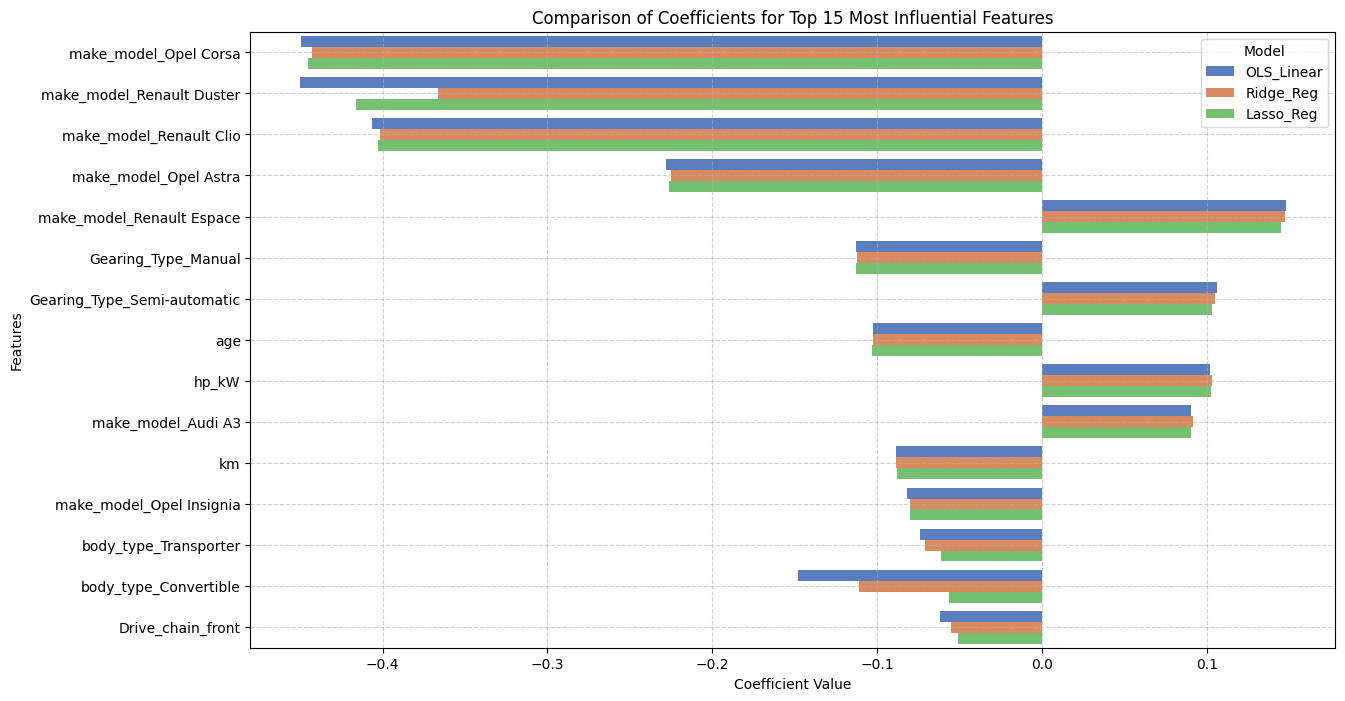

In [55]:
# Plotting the comparison for the top 15 features
top_15_features = coef_comparison_sorted.head(15)

melted_coefs = top_15_features.melt(id_vars='Feature', value_vars=['OLS_Linear', 'Ridge_Reg', 'Lasso_Reg'],
                                    var_name='Model', value_name='Coefficient')

plt.figure(figsize=(14, 8))
sns.barplot(data=melted_coefs, y='Feature', x='Coefficient', hue='Model', palette='muted')
plt.title('Comparison of Coefficients for Top 15 Most Influential Features')
plt.xlabel('Coefficient Value')
plt.ylabel('Features')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [56]:
# Identify and display the coefficients of features that Lasso dropped (shrunk to exactly 0)
shrunk_features = coef_comparison[coef_comparison['Lasso_Reg'] == 0].drop(columns=['Abs_Lasso_Coef'])

print(f"Features completely dropped (shrunk to 0) by the Lasso Model (Total: {len(shrunk_features)}):")
display(shrunk_features.round(6))


Features completely dropped (shrunk to 0) by the Lasso Model (Total: 5):


,Feature,OLS_Linear,Ridge_Reg,Lasso_Reg
22,Comfort_Convenience_Rain sensor,-0.001199,-0.001044,-0.0
68,Safety_Security_Head airbag,0.000851,0.000796,0.0
69,Safety_Security_Alarm system,-0.001001,-0.000593,-0.0
80,make_model_Audi A2,0.000000,0.000000,0.0
105,Drive_chain_rear,-0.129488,-0.075302,-0.0


## **4 Conclusion & Key Takeaways**  <font color =red> [10 marks] </font>

What did you notice by performing regularisation? Did the model performance improve? If not, then why? Did you find overfitting or not? Was the data sufficent? Is a linear model sufficient?

#### **4.1 Conclude with outcomes and insights gained** <font color =red> [10 marks] </font>

By comparing the models and analyzing the regularisation results, we can draw several key insights:

1. Impact of Regularisation and Performance
Did the performance improve? Yes, but by an extremely small margin.
Baseline OLS R²: 0.93333
Ridge R²: 0.93337
Lasso R²: 0.93359
Why was the improvement so minor? Regularisation (L1/L2) helps most when there is significant overfitting or extreme multicollinearity. Because our baseline Ordinary Least Squares (OLS) model was already performing remarkably well and generalizes almost perfectly to the test set, there was very little room for shrinkage or penalty to improve the overall metrics.
2. Overfitting Analysis
Did we find overfitting? No. The baseline OLS model scored an R² of 0.9279 on the training set and 0.9333 on the test set. Because the test set performance is actually slightly better than (or practically equal to) the training performance, the model shows zero signs of overfitting. It generalized beautifully without memorizing noise.
3. Data Sufficiency
Was the data sufficient? Yes. With 15,915 records and a clean distribution across various makes, models, and specifications, the dataset was highly sufficient. The feature engineering steps—such as unpacking the nested list columns (Comfort_Convenience, Safety_Security, etc.) and using frequency-based thresholds—provided rich, high-quality predictive signals that allowed the linear models to easily learn the mapping to car prices.
4. Is a Linear Model Sufficient?
Yes, a linear model is highly sufficient. Achieving an R² of over 93.3% on a log-transformed target variable (log_price) indicates that the relationships between our engineered features (such as vehicle age, mileage km, engine power hp_kW, and brand/model) and the price are strongly linear in log-space.
While non-linear models (like Gradient Boosting or Random Forests) might squeeze out a tiny bit more performance, the linear regression framework here is extremely powerful, highly interpretable, and computationally lightweight.